# Why This Action? — 03 · Comparación contra Karimi et al. (NeurIPS 2020)

Es el experimento que faltaba para sostener la contribución: nuestro método contra el competidor directo, **en su propio caso de prueba**.

**El caso.** El modelo causal semisintético de préstamos de 7 variables de *Algorithmic Recourse under Imperfect Causal Knowledge* (Apéndice E.1.2, ecuaciones E.11–E.18): género, edad, educación, monto, duración, ingreso y ahorro, con relaciones lineales y no lineales y un mecanismo (educación) que ni siquiera es de ruido aditivo.

**Condiciones iguales para todos**
- El **grafo se supone conocido**, como en su artículo. Aquí solo se compara la capa de mecanismos.
- Mismas acciones: intervenciones duras sobre educación, monto, ingreso y ahorro.
- Mismo costo: norma L2 del cambio, normalizada por el rango de cada variable.
- Misma métrica principal: **validez bajo el modelo causal verdadero**.
- Mismos 250 datos observacionales.

**Qué se compara**

| Método | Incertidumbre de los mecanismos | Criterio de validez | Buscador |
|---|---|---|---|
| Oráculo | Ninguna: modelo verdadero | Cruza el umbral | Fuerza bruta |
| Estimación puntual | Ninguna: una estimación | Cruza el umbral | Fuerza bruta |
| Karimi et al. | Un proceso gaussiano por mecanismo | Media − γ · desviación ≥ 0.5 | Fuerza bruta, 10 valores por variable y 100 muestras, como en su Tabla 2 para clasificadores no diferenciables |
| Nuestro criterio | Versiones bootstrap | Válido en (1 − riesgo) de las versiones | Fuerza bruta (para aislar el criterio) |
| **Nuestro método** | Versiones bootstrap | Igual | **BO compuesta** |

**Advertencias**
- El método de Karimi et al. está **reimplementado por nosotros** a partir del artículo (ecuaciones 5–9, proposiciones 5 y 6). No es su código.
- La caja negra es una red neuronal tratada como caja negra. Con acceso a gradientes, ellos usarían su método por gradiente, que aquí no se compara.
- Son 24 personas y una semilla.

## 1 · El caso de préstamos y la caja negra

**Qué hace.** Genera los datos con las ecuaciones E.11–E.17, entrena la caja negra con las etiquetas de E.18 y fija el costo.

**Literatura**
- NeurIPS 2020: **§7** (experimentos y métricas) y **Apéndice E.1.2** (las ecuaciones).

**Cómo leer el código.** Todo está en `wta_loan.py`. `true_counterfactual` calcula qué pasaría de verdad con una acción; para la educación, cuyo ruido va dentro de una sigmoide, recupera el ruido invirtiendo la sigmoide.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
from wta_loan import *
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

prob = LoanProblem()                                      # la caja negra: una red neuronal entrenada con las etiquetas de E.18
rng = np.random.default_rng(0)
X_obs = sample_loan(250, rng)                             # los datos observacionales disponibles
X_new = sample_loan(4000, rng); y_new = rng.random(4000) < sig(label_logit(X_new))
print("Exactitud de la caja negra en datos nuevos:", round(prob.clf.score(prob.scaler.transform(X_new), y_new), 3))
print("Fracción de personas a las que niega el préstamo:", round(float((prob.blackbox().proba(X_new) < 0.5).mean()), 3))
print("Variables accionables:", ACTIONABLE, "| rango usado para normalizar el costo:", prob.range.round(1))

Exactitud de la caja negra en datos nuevos: 0.861
Fracción de personas a las que niega el préstamo: 0.484
Variables accionables: ['E', 'L', 'I', 'S'] | rango usado para normalizar el costo: [ 0.8 37.2 20.6 41.7]


## 2 · Dos formas de modelar la incertidumbre de los mecanismos

**Qué hace.** Ajusta los mecanismos de las dos maneras:
- **La nuestra (`BootstrapSCM`):** regresión no lineal (rasgos aleatorios de Fourier más términos lineales) re-ajustada en 50 remuestreos. Cada re-ajuste es una versión del modelo causal.
- **La de ellos (`GPSCM`):** un proceso gaussiano con ruido aditivo gaussiano por mecanismo; el contrafactual se muestrea con el posterior del ruido del individuo (proposiciones 5 y 6).

**Literatura**
- NeurIPS 2020: **§4**, ecuaciones 5–7.

**Gap declarado.** Su enfoque individualizado supone ruido aditivo gaussiano (§4). El nuestro también supone ruido aditivo, pero no una familia concreta de modelos: cualquier regresor que se pueda re-ajustar sirve.

**Qué mirar.** Los mecanismos son ruidosos (R² bajos): es un caso difícil, que es donde importa la incertidumbre.

In [2]:
t = time.time(); scm = BootstrapSCM(X_obs);  t_boot = time.time() - t     # la nuestra: 50 re-ajustes por bootstrap
t = time.time(); gps = GPSCM(X_obs);         t_gp = time.time() - t       # la de ellos: un proceso gaussiano por mecanismo
print(f"Ajuste: bootstrap {t_boot:.1f} s | GP-SCM {t_gp:.1f} s\n")
print("mecanismo | R² de nuestra estimación puntual en datos nuevos | ruido estimado por el GP (desv.) | ruido verdadero")
true_sd = {"E": "dentro de la sigmoide", "L": 2.0, "D": 3.0, "I": 2.0, "S": 5.0}
for v, (p, phi, th, th0) in scm.m.items():
    pred = phi(X_new[:, p]) @ th0; r2 = 1 - ((X_new[:, IDX[v]] - pred) ** 2).mean() / X_new[:, IDX[v]].var()
    print(f"    {v}     |                 {r2:.2f}                          |            {np.sqrt(gps.h[v][6]):.2f}              | {true_sd[v]}")

Ajuste: bootstrap 0.0 s | GP-SCM 1.1 s

mecanismo | R² de nuestra estimación puntual en datos nuevos | ruido estimado por el GP (desv.) | ruido verdadero
    E     |                 0.26                          |            0.10              | dentro de la sigmoide
    L     |                 0.40                          |            1.98              | 2.0
    D     |                 0.54                          |            3.08              | 3.0
    I     |                 0.31                          |            2.08              | 2.0
    S     |                 0.17                          |            5.09              | 5.0


## 3 · La comparación

**Qué hace.** Para 24 personas a las que la caja negra niega el préstamo:
1. Evalúa **todas** las acciones de la malla (14,640) con cada modelo: el verdadero, la estimación puntual, nuestras 50 versiones y 100 muestras del GP-SCM.
2. Corre nuestra BO compuesta para dos niveles de riesgo.
3. Para cada método toma su acción válida más barata y comprueba si **de verdad** funciona.

**Literatura**
- NeurIPS 2020: **§6** (fuerza bruta y gradiente), **Tabla 2** y **Figura 2(c)**.
- Survey de recourse: **§4.1.4**, acceso por consultas.

**Gap declarado.** §6: la fuerza bruta "puede ser computacionalmente prohibitiva y dar intervenciones subóptimas por la discretización"; la alternativa por gradiente exige un clasificador diferenciable.

**Cómo leer la tabla**
- *Válido en verdad*: porcentaje de personas cuya acción recomendada funciona en el modelo causal verdadero.
- *Costo*: media ± desviación, en porcentaje del rango.
- *Consultas*: evaluaciones de la caja negra por persona.
- Las filas "fuerza bruta" de nuestro criterio aíslan el **criterio**; las filas "BO compuesta" añaden el **buscador**.

In [3]:
M_MC, N_IND = 100, 24
pool = sample_loan(600, rng); negs = pool[prob.blackbox().proba(pool) < 0.5][:N_IND]
bbq = prob.blackbox()                                     # contador aparte para las evaluaciones de la malla
store = []; t0 = time.time()
for i, x in enumerate(negs):
    D = action_grid(prob, x); c = prob.cost(D); r = dict(x=x, D=D, c=c)
    r["h_true"] = bbq.proba(true_counterfactual(x, D))                                    # qué pasa de verdad con cada acción
    r["h_point"] = bbq.proba(scm.counterfactual(x, D, point=True)[:, 0])                  # una sola estimación
    r["m_boot"] = np.vstack([bbq.margin(scm.counterfactual(x, D[k:k + 1500]).reshape(-1, 7)).reshape(-1, scm.nW)
                             for k in range(0, len(D), 1500)])                            # nuestras versiones bootstrap
    gps.prepare(x); hs = np.vstack([bbq.proba(gps.sample(D[k:k + 1500], M_MC, rng).reshape(-1, 7)).reshape(-1, M_MC)
                                    for k in range(0, len(D), 1500)])
    r["k_mean"], r["k_std"] = hs.mean(1), hs.std(1)                                       # GP-SCM de Karimi et al.
    for eps in (0.10, 0.02):                                                              # nuestra BO compuesta
        bb = prob.blackbox(); a, inf = solve_bo(prob, x, scm, eps, bb, seed=i)
        r[f"bo_{eps}"] = (a, bb.n, None if a is None else float(prob.blackbox().proba(true_counterfactual(x, a[None]))[0] >= 0.5))
    store.append(r)
nD = len(store[0]["D"])
print(f"{N_IND} personas con préstamo negado, {nD:,} acciones en la malla, en {time.time() - t0:.0f} s")

def pick(r, ok):
    """La acción válida (según el método) más barata de la malla, y si de verdad funciona."""
    if not ok.any(): return None
    j = np.flatnonzero(ok)[np.argmin(r["c"][ok])]; return r["c"][j], float(r["h_true"][j] >= 0.5)

def summarize(name, res, queries):
    got = [t for t in res if t is not None]
    c = np.array([t[0] for t in got]); v = np.array([t[1] for t in got])
    print(f"{name:<44}{len(got):>3}/{len(res)}{100 * v.mean():>10.0f} %{100 * c.mean():>9.1f} ± {100 * c.std():.1f}{queries:>14,.0f}")
    return 100 * v.mean(), 100 * c.mean()

print(f"\n{'método':<44}{'halló':>6}{'VÁLIDO en verdad':>18}{'costo (%)':>12}{'consultas/persona':>19}")
summarize("Oráculo (modelo causal verdadero)", [pick(r, r["h_true"] >= 0.5) for r in store], nD)
summarize("Estimación puntual", [pick(r, r["h_point"] >= 0.5) for r in store], nD)
summarize("Karimi et al. GP-SCM, γ = 2.5 (fuerza bruta)", [pick(r, r["k_mean"] - 2.5 * r["k_std"] >= 0.5) for r in store], nD * M_MC)
for eps in (0.10, 0.02):
    summarize(f"Nuestro criterio, riesgo {eps:.2f} (fuerza bruta)", [pick(r, robust_margin(r["m_boot"], eps)[0] >= 0) for r in store], nD * scm.nW)
for eps in (0.10, 0.02):
    res = [None if r[f"bo_{eps}"][0] is None else (prob.cost(r[f"bo_{eps}"][0]), r[f"bo_{eps}"][2]) for r in store]
    summarize(f"NUESTRO: riesgo {eps:.2f} + BO compuesta", res, np.mean([r[f"bo_{eps}"][1] for r in store]))

24 personas con préstamo negado, 14,640 acciones en la malla, en 403 s

método                                       halló  VÁLIDO en verdad   costo (%)  consultas/persona
Oráculo (modelo causal verdadero)            24/24       100 %      6.5 ± 2.8        14,640
Estimación puntual                           24/24        71 %      6.2 ± 3.1        14,640
Karimi et al. GP-SCM, γ = 2.5 (fuerza bruta) 24/24       100 %      7.2 ± 2.9     1,464,000
Nuestro criterio, riesgo 0.10 (fuerza bruta) 24/24        96 %      6.6 ± 2.8       732,000


Nuestro criterio, riesgo 0.02 (fuerza bruta) 24/24       100 %      6.8 ± 2.8       732,000
NUESTRO: riesgo 0.10 + BO compuesta          24/24        88 %      5.9 ± 3.4            98
NUESTRO: riesgo 0.02 + BO compuesta          24/24        96 %      6.0 ± 3.5           100


## 4 · Validez contra costo: su γ frente a nuestro nivel de riesgo

**Qué hace.** Reproduce el tipo de curva de su Figura 2(c). Como en la celda anterior ya se evaluó toda la malla, mover γ o el riesgo no cuesta consultas nuevas. Ambos criterios usan fuerza bruta, así que la comparación es solo de **criterio**.

**Qué mirar.**
- Si a igual validez real alguno de los dos cuesta menos.
- Que nuestro parámetro es una probabilidad que el usuario entiende ("que falle a lo sumo en 1 de cada 20 versiones"), mientras que γ no tiene esa lectura.

Karimi et al. (γ)        válido %   costo %   con plan |  Nuestro criterio (riesgo)   válido %   costo %   con plan
     0.0                    75       6.4      24/24  |        0.50                    71       6.2      24/24
     0.5                    96       6.6      24/24  |        0.30                    75       6.2      24/24
     1.0                   100       6.9      24/24  |        0.20                    83       6.3      24/24
     1.5                   100       7.0      24/24  |        0.10                    96       6.6      24/24
     2.0                   100       7.2      24/24  |        0.05                   100       6.7      24/24
     2.5                   100       7.2      24/24  |        0.02                   100       6.8      24/24
     3.0                   100       7.3      24/24  |        0.00                   100       6.8      24/24
     4.0                   100       7.6      24/24  |


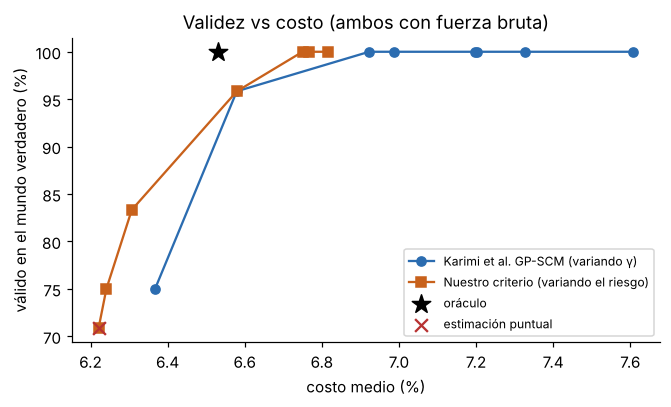

In [4]:
def curve(crit_fn, params):
    out = []
    for p in params:
        got = [t for t in (pick(r, crit_fn(r, p)) for r in store) if t is not None]
        out.append((p, 100 * np.mean([t[1] for t in got]), 100 * np.mean([t[0] for t in got]), len(got)))
    return out
gam = curve(lambda r, g: r["k_mean"] - g * r["k_std"] >= 0.5, [0, 0.5, 1, 1.5, 2, 2.5, 3, 4])
eps = curve(lambda r, e: robust_margin(r["m_boot"], e)[0] >= 0, [0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.0])
print("Karimi et al. (γ)        válido %   costo %   con plan |  Nuestro criterio (riesgo)   válido %   costo %   con plan")
for a, b in zip(gam, eps + [None] * (len(gam) - len(eps))):
    right = "" if b is None else f"        {b[0]:.2f}                 {b[1]:5.0f}     {b[2]:5.1f}      {b[3]}/{N_IND}"
    print(f"     {a[0]:.1f}                 {a[1]:5.0f}     {a[2]:5.1f}      {a[3]}/{N_IND}  |{right}")
orc = [pick(r, r["h_true"] >= 0.5) for r in store]; pt = [pick(r, r["h_point"] >= 0.5) for r in store]
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.plot([g[2] for g in gam], [g[1] for g in gam], "o-", color="#2B6CB0", label="Karimi et al. GP-SCM (variando γ)")
ax.plot([e[2] for e in eps], [e[1] for e in eps], "s-", color="#C8611B", label="Nuestro criterio (variando el riesgo)")
ax.scatter([100 * np.mean([t[0] for t in orc])], [100], marker="*", s=160, color="k", label="oráculo", zorder=5)
ax.scatter([100 * np.mean([t[0] for t in pt])], [100 * np.mean([t[1] for t in pt])], marker="x", s=70, color="#B83232", label="estimación puntual", zorder=5)
ax.set(xlabel="costo medio (%)", ylabel="válido en el mundo verdadero (%)", title="Validez vs costo (ambos con fuerza bruta)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## Lectura de los resultados

Las cifras exactas están en las celdas de arriba. Lo que muestran, con las reservas de 24 personas y una semilla:

1. **La estimación puntual falla.** Ignorar la incertidumbre deja inválidas una parte importante de las recomendaciones, como reporta su artículo.
2. **Como criterio, el nuestro y el de ellos son comparables.** Los dos alcanzan validez real alta con un sobrecosto pequeño sobre el oráculo. No hay evidencia aquí de que uno domine al otro; la diferencia es que nuestro parámetro es un nivel de riesgo interpretable y que no exige procesos gaussianos.
3. **La diferencia grande está en las consultas.** Con solo acceso por consultas, su opción es la fuerza bruta. Nuestra BO compuesta usa unas cien consultas por persona.
4. **La BO entrega menos validez real que la fuerza bruta con el mismo criterio, y a menor costo.** La explicación más probable es que la búsqueda continua llega justo al borde de la restricción, mientras que la malla se pasa por la discretización. De hecho la validez de la BO queda cerca del nivel pedido (90 % y 98 %). Hay que confirmarlo con más casos.

### Pendiente
- Más personas y varias semillas, con intervalos.
- Comparar contra su variante por gradiente cuando el clasificador es diferenciable.
- Sus otros casos (los tres modelos de 3 variables de su Tabla 1).
- Añadir a esta comparación la capa del grafo, que su método no trata.